**Portafolio de Data Science**
# MODELO HIBRIDO DE MACHINE LEARNING: LSTM + Regresión Lineal

**Por Carlos A. Ugarte**

**Enfoque conceptual:** serie de cierres, ventanas de 60 sesiones, LSTM de dos capas de 50 unidades, regresión lineal con tres rezagos, combinación ponderada y pronóstico recursivo de diez sesiones.

**Aspectos esenciales:** se utiliza el CSV adjunto (2010–2020); orden cronológico; escalador entrenado solo con entrenamiento; muestras de ambos modelos alineadas por fecha; conjunto de validación independiente para elegir el peso; prueba final no utilizada para elegir hiperparámetros; comparación con persistencia; fechas hábiles aproximadas y advertencias de sesgo.

**Limitación:** los precios originales no están ajustados por eventos corporativos. No usar para inversión.

## 1. Configuración y entorno
Usá **Python 3.11 de 64 bits** en un entorno virtual. En Windows seguí `docs/GUIA_INSTALACION_WINDOWS.md`.

El notebook imprime `sys.executable` para comprobar el intérprete. Si falta una dependencia, instalala en ese intérprete, no en el Python global. Abrí VS Code desde la raíz del proyecto, que contiene la carpeta `data/`.


In [1]:
from pathlib import Path
import random
import sys
print("Intérprete de Jupyter:",sys.executable)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEMILLA = 42
np.random.seed(SEMILLA)
random.seed(SEMILLA)
VENTANA = 60
EPOCAS = 20
LOTE = 32
USAR_LSTM = True  # poner False si no se dispone de TensorFlow

candidatas = [Path("data/precios_historicos_normalizados.csv"),
              Path("../data/precios_historicos_normalizados.csv")]
ruta = next((p for p in candidatas if p.exists()), None)
if ruta is None:
    raise FileNotFoundError("No se encontró data/precios_historicos_normalizados.csv. Ejecutá desde la raíz del repositorio.")
datos = pd.read_csv(ruta, parse_dates=["Fecha"]).sort_values("Fecha").reset_index(drop=True)
print("Dataset:",ruta.resolve(), "| Filas:",len(datos))
display(datos.head())

Intérprete de Jupyter: c:\Users\Charly\.venv\Scripts\python.exe
Dataset: C:\Mis Documentos\My_Career_Strategy\12_MisProyectos\04_Modelo_Hibrido_ML_Python_Prediccion _Precio_Accion\data\precios_historicos_normalizados.csv | Filas: 2518


,Fecha,Cierre,Apertura,Maximo,Minimo,Volumen
0,2010-03-01,29.8557,29.3928,29.9286,29.3500,137312041
1,2010-03-02,29.8357,29.9900,30.1186,29.6771,141486282
2,2010-03-03,29.9043,29.8486,29.9814,29.7057,92846488
3,2010-03-04,30.1014,29.8971,30.1314,29.8043,89591907
4,2010-03-05,31.2786,30.7057,31.3857,30.6614,224647427


## 2. Auditoría de datos
Se evalúan integridad, unicidad temporal y consistencia de OHLC. El origen bursátil exacto, la moneda, los ajustes por dividendos y splits no están certificados.

Intervalo: 2010-03-01 a 2020-02-28
Registros: 2518


,Fecha,Cierre,Apertura,Maximo,Minimo,Volumen
count,2518,2518.000000,2518.000000,2518.000000,2518.000000,2.518000e+03
mean,2015-02-26 15:01:17.204130304,114.769522,114.728443,115.766415,113.690582,7.258009e+07
min,2010-03-01 00:00:00,29.835700,29.392800,29.928600,28.464300,1.136205e+07
25%,2012-08-24 18:00:00,66.822475,66.877150,67.475300,66.372950,3.053026e+07
50%,2015-02-28 12:00:00,101.090000,101.115000,102.085000,100.350000,5.295469e+07
75%,2017-08-27 06:00:00,154.630000,154.610000,155.735000,153.325000,9.861006e+07
max,2020-02-28 00:00:00,327.200000,324.740000,327.850000,323.350000,4.624423e+08
std,NaN,60.662405,60.546893,61.134456,60.085105,5.663113e+07


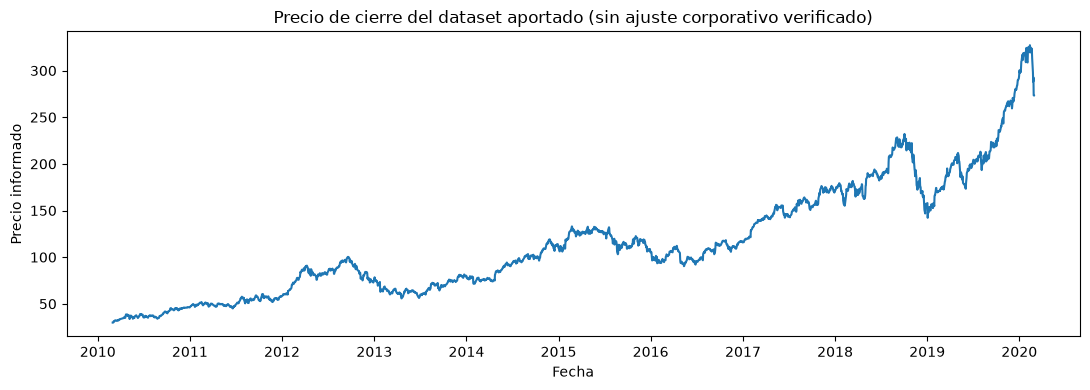

In [2]:
assert datos["Fecha"].is_monotonic_increasing
assert not datos["Fecha"].duplicated().any()
assert datos[["Cierre","Apertura","Maximo","Minimo","Volumen"]].notna().all().all()
assert (datos[["Cierre","Apertura","Maximo","Minimo"]] > 0).all().all()
assert (datos["Volumen"] >= 0).all()
assert (datos["Maximo"] >= datos[["Apertura","Cierre","Minimo"]].max(axis=1)).all()
assert (datos["Minimo"] <= datos[["Apertura","Cierre","Maximo"]].min(axis=1)).all()
print("Intervalo:",datos["Fecha"].min().date(),"a",datos["Fecha"].max().date())
print("Registros:",len(datos))
display(datos.describe())
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(datos["Fecha"],datos["Cierre"])
ax.set(title="Precio de cierre del dataset aportado (sin ajuste corporativo verificado)",
       xlabel="Fecha",ylabel="Precio informado")
plt.tight_layout();plt.show()

## 3. Partición temporal y escalado sin fuga de información
Se separan cronológicamente **70 % entrenamiento, 15 % validación y 15 % prueba**. El `MinMaxScaler` se ajusta exclusivamente con entrenamiento; transformar validación/prueba no modifica sus parámetros. Se construye cada muestra para predecir el cierre del día *t* utilizando exclusivamente observaciones anteriores a *t*. La misma fecha objetivo se usa en LSTM, regresión y persistencia.

In [3]:
cierres = datos["Cierre"].to_numpy(dtype=float)
fechas = datos["Fecha"].to_numpy()
n = len(cierres)
fin_train = int(n * .70)
fin_val = int(n * .85)
assert fin_train > VENTANA and fin_val > fin_train
scaler = MinMaxScaler()
scaler.fit(cierres[:fin_train].reshape(-1,1))
escalados = scaler.transform(cierres.reshape(-1,1)).ravel()

indices = np.arange(VENTANA,n)
X_seq = np.stack([escalados[t-VENTANA:t] for t in indices])
X_lag = np.stack([[escalados[t-1],escalados[t-2],escalados[t-3]] for t in indices])
y = escalados[indices]
y_real = cierres[indices]
f_obj = fechas[indices]
m_train = indices < fin_train
m_val = (indices >= fin_train) & (indices < fin_val)
m_test = indices >= fin_val
for nombre,m in [("Entrenamiento",m_train),("Validación",m_val),("Prueba",m_test)]:
    print(nombre, m.sum(),pd.Timestamp(f_obj[m][0]).date(),pd.Timestamp(f_obj[m][-1]).date())
assert not set(indices[m_train]).intersection(indices[m_val])
assert not set(indices[m_val]).intersection(indices[m_test])

Entrenamiento 1702 2010-05-25 2017-02-27
Validación 378 2017-02-28 2018-08-27
Prueba 378 2018-08-28 2020-02-28


## 4. Baselines: persistencia y regresión lineal
La persistencia pronostica que el próximo cierre será igual al último observado. Es una referencia exigente para series de precios. La regresión usa los tres cierres anteriores en orden `[t−1, t−2, t−3]`.

In [4]:
lineal = LinearRegression()
lineal.fit(X_lag[m_train], y[m_train])
pred_lineal_val = scaler.inverse_transform(lineal.predict(X_lag[m_val]).reshape(-1,1)).ravel()
pred_lineal_test = scaler.inverse_transform(lineal.predict(X_lag[m_test]).reshape(-1,1)).ravel()
pred_persist_val = cierres[indices[m_val]-1]
pred_persist_test = cierres[indices[m_test]-1]

## 5. Red LSTM
Se replica la arquitectura conceptual de la fuente: dos capas LSTM de 50 unidades y una capa densa de salida, con Adam y error cuadrático medio. Se ajusta con **solo entrenamiento**; la validación sirve para monitorear, no para actualizar pesos. La ejecución con TensorFlow puede variar entre sistemas y requiere más tiempo que la regresión.

In [5]:
if USAR_LSTM:
    try:
        import tensorflow as tf
    except ImportError as exc:
        raise RuntimeError(
            f"No se pudo cargar TensorFlow desde {sys.executable}. "
            "Puede faltar la biblioteca o fallar una DLL nativa. "
            "Consultá docs/GUIA_INSTALACION_WINDOWS.md."
        ) from exc
    tf.keras.utils.set_random_seed(SEMILLA)
    modelo_lstm = tf.keras.Sequential([
        tf.keras.Input(shape=(VENTANA,1)),
        tf.keras.layers.LSTM(50,return_sequences=True),
        tf.keras.layers.LSTM(50),
        tf.keras.layers.Dense(1)
    ])
    modelo_lstm.compile(optimizer="adam",loss="mean_squared_error")
    historial = modelo_lstm.fit(
        X_seq[m_train][...,None],y[m_train],
        validation_data=(X_seq[m_val][...,None],y[m_val]),
        epochs=EPOCAS,batch_size=LOTE,shuffle=False,verbose=1
    )
    pred_lstm_val = scaler.inverse_transform(
        modelo_lstm.predict(X_seq[m_val][...,None],verbose=0)).ravel()
    pred_lstm_test = scaler.inverse_transform(
        modelo_lstm.predict(X_seq[m_test][...,None],verbose=0)).ravel()
else:
    modelo_lstm = None
    pred_lstm_val = pred_lstm_test = None
    print("Modo sin TensorFlow: se evalúan únicamente los modelos de referencia.")

Epoch 1/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 13s 91ms/step - loss: 0.0082 - val_loss: 0.0376
Epoch 2/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - loss: 0.0134 - val_loss: 0.0073
Epoch 3/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - loss: 0.0034 - val_loss: 0.0060
Epoch 4/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - loss: 0.0012 - val_loss: 0.0053
Epoch 5/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - loss: 0.0014 - val_loss: 0.0042
Epoch 6/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - loss: 0.0013 - val_loss: 0.0052
Epoch 7/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step - loss: 0.0013 - val_loss: 0.0031
Epoch 8/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - loss: 0.0013 - val_loss: 0.0035
Epoch 9/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - loss: 0.0013 - val_loss: 0.0025
Epoch 10/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - loss: 0.0012 - val_loss: 0.0025
Epoch 11/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - loss: 0.0011 - val_loss: 0.0022
Epoch 12/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - loss: 9.

## 6. Selección del peso híbrido en validación
Se utiliza **70 % LSTM + 30 % regresión lineal**. Se muestra esa combinación como referencia. Para evitar elegir el peso usando el conjunto de prueba, se compara una cuadrícula de pesos sobre **validación** y se fija el ganador antes de calcular las métricas finales. Una búsqueda de pesos puede sobreajustar validación; por eso se conserva el baseline y se recomienda evaluación walk-forward en futuros trabajos.

In [6]:
def metricas(verdad,pred):
    return {"MAE":mean_absolute_error(verdad,pred),
            "RMSE":np.sqrt(mean_squared_error(verdad,pred)),
            "MAPE_%":100*np.mean(np.abs((verdad-pred)/verdad))}

resultados = {
    "Persistencia": pred_persist_test,
    "Regresión lineal": pred_lineal_test
}
if USAR_LSTM:
    resultados["LSTM"] = pred_lstm_test
    resultados["Híbrido 70/30 (artículo)"] = .7*pred_lstm_test+.3*pred_lineal_test
    pesos = np.arange(0,1.01,.1)
    errores_val = [mean_absolute_error(y_real[m_val],w*pred_lstm_val+(1-w)*pred_lineal_val) for w in pesos]
    peso_opt = float(pesos[int(np.argmin(errores_val))])
    resultados["Híbrido validado"] = peso_opt*pred_lstm_test+(1-peso_opt)*pred_lineal_test
    print(f"Peso seleccionado en validación: LSTM={peso_opt:.1f}, lineal={1-peso_opt:.1f}")
else:
    peso_opt = None
tabla = pd.DataFrame({nombre:metricas(y_real[m_test],p) for nombre,p in resultados.items()}).T
display(tabla.sort_values("MAE"))

Peso seleccionado en validación: LSTM=0.0, lineal=1.0


,MAE,RMSE,MAPE_%
Persistencia,2.907143,4.019740,1.361305
Regresión lineal,2.917556,4.019985,1.365949
Híbrido validado,2.917556,4.019985,1.365949
Híbrido 70/30 (artículo),9.091418,12.592973,3.724339
LSTM,12.478155,17.478569,5.064033


## 7. Evaluación temporal visual y error frente a persistencia
La comparación debe hacerse sobre las mismas fechas objetivo. Un híbrido no es automáticamente mejor: si no supera a persistencia, no hay evidencia de mejora predictiva en esta partición.

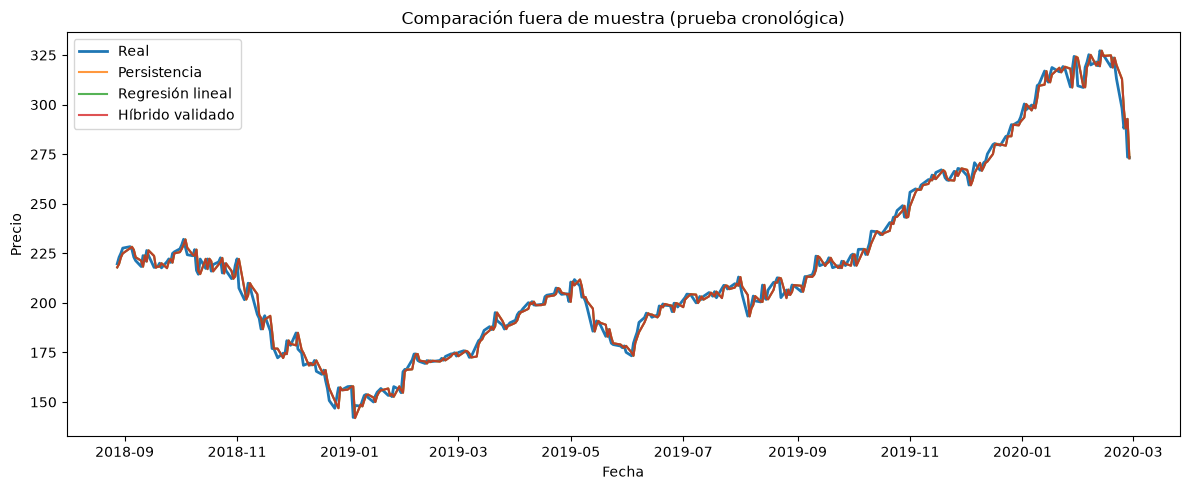

Reducción MAE frente a persistencia (positiva = mejora): -0.0104


In [7]:
fig,ax=plt.subplots(figsize=(12,5))
ax.plot(pd.to_datetime(f_obj[m_test]),y_real[m_test],label="Real",linewidth=2)
for nombre,pred in resultados.items():
    if nombre in ["Persistencia","Híbrido validado","Regresión lineal"] or (nombre=="LSTM" and not USAR_LSTM):
        ax.plot(pd.to_datetime(f_obj[m_test]),pred,label=nombre,alpha=.8)
ax.set(title="Comparación fuera de muestra (prueba cronológica)",xlabel="Fecha",ylabel="Precio")
ax.legend();plt.tight_layout();plt.show()
if USAR_LSTM:
    mejor = resultados["Híbrido validado"]
    diferencia = metricas(y_real[m_test],pred_persist_test)["MAE"] - metricas(y_real[m_test],mejor)["MAE"]
    print("Reducción MAE frente a persistencia (positiva = mejora):",round(diferencia,4))

## 8. Pronóstico recursivo de 10 sesiones
Para cada modelo se realimenta su propia predicción, **sin utilizar valores futuros observados**. En la regresión, los rezagos se ordenan `[último, penúltimo, antepenúltimo]` de forma idéntica al entrenamiento. Se calculan diez **días hábiles aproximados** (no se excluyen feriados bursátiles). La incertidumbre aumenta con el horizonte; no se proporcionan intervalos calibrados.

In [8]:
def pronostico_lineal_recursivo(modelo,serie,horizonte=10):
    historico=list(serie)
    salidas=[]
    for _ in range(horizonte):
        x=np.array([[historico[-1],historico[-2],historico[-3]]])
        estimado=float(modelo.predict(x)[0])
        salidas.append(estimado)
        historico.append(estimado)
    return np.array(salidas)

HORIZONTE=10
fut_lin_escalado=pronostico_lineal_recursivo(lineal,escalados,HORIZONTE)
fut_lin=scaler.inverse_transform(fut_lin_escalado.reshape(-1,1)).ravel()
fut_persist=np.repeat(cierres[-1],HORIZONTE)
pronosticos={"Persistencia":fut_persist,"Regresión lineal":fut_lin}
if USAR_LSTM:
    ventana=list(escalados[-VENTANA:])
    fut_lstm_escalado=[]
    for _ in range(HORIZONTE):
        pred=float(modelo_lstm.predict(np.array(ventana[-VENTANA:]).reshape(1,VENTANA,1),verbose=0)[0,0])
        fut_lstm_escalado.append(pred)
        ventana.append(pred)
    fut_lstm=scaler.inverse_transform(np.array(fut_lstm_escalado).reshape(-1,1)).ravel()
    pronosticos["LSTM"]=fut_lstm
    pronosticos["Híbrido 70/30"]=.7*fut_lstm+.3*fut_lin
    pronosticos["Híbrido validado"]=peso_opt*fut_lstm+(1-peso_opt)*fut_lin
fechas_futuras=pd.bdate_range(datos["Fecha"].iloc[-1]+pd.Timedelta(days=1),periods=HORIZONTE)
tabla_futura=pd.DataFrame({"Fecha":fechas_futuras,**pronosticos})
display(tabla_futura)

,Fecha,Persistencia,Regresión lineal,LSTM,Híbrido 70/30,Híbrido validado
0,2020-03-02,273.36,273.672564,262.639022,265.949084,273.672564
1,2020-03-03,273.36,273.547795,258.339102,262.901710,273.547795
2,2020-03-04,273.36,273.402918,254.019412,259.834464,273.402918
3,2020-03-05,273.36,273.268072,249.797295,256.838528,273.268072
4,2020-03-06,273.36,273.134046,245.726717,253.948916,273.134046
5,2020-03-09,273.36,272.999938,241.834789,251.184334,272.999938
6,2020-03-10,273.36,272.865946,238.132815,248.552754,272.865946
7,2020-03-11,273.36,272.732096,234.623008,246.055734,272.732096
8,2020-03-12,273.36,272.598383,231.302618,243.691347,272.598383
9,2020-03-13,273.36,272.464806,228.165967,241.455619,272.464806


## 9. Exportación, interpretación y límites
Los resultados se guardan en `outputs/` (excluido de Git). La predicción se refiere a la **serie histórica cargada**, cuyo período termina en 2020; **no** es un pronóstico vigente de mercado en 2026. Las métricas del test son observaciones de una sola partición, no evidencia de robustez general. Para investigación adicional: backtesting walk-forward, intervalos de predicción, ajuste de splits/dividendos, evaluación de retorno y costos de transacción.

In [9]:
salida=Path("outputs")
salida.mkdir(exist_ok=True)
tabla.to_csv(salida/"metricas_test.csv",index_label="Modelo")
tabla_futura.to_csv(salida/"pronosticos_10_sesiones.csv",index=False)
print("Archivos exportados en:",salida.resolve())

Archivos exportados en: C:\Mis Documentos\My_Career_Strategy\12_MisProyectos\04_Modelo_Hibrido_ML_Python_Prediccion _Precio_Accion\outputs
